# Multi-Layer Perceptron (MLP) Model (apartment data)

In this notebook, we will use a Multi-Layer Perceptron (MLP) Model to predict rental prices of apartments. A Multi-Layer Perceptron (MLP) model is a type of artificial neural network that consists of multiple layers of neurons. Each neuron in a layer is connected to every neuron in the previous and next layers, forming a fully connected network. The MLP model is capable of learning complex patterns in the data through backpropagation and gradient descent.

The key components of an MLP model include:
- **Input Layer**: The layer that receives the input features.
- **Hidden Layers**: One or more layers with weights and activation functions to learn intermediate representations.
- **Output Layer**: The layer that produces the final prediction.

In this notebook, we will:
1. Preprocess the apartment data, including scaling the features.
2. Define and compile the MLP model using TensorFlow/Keras.
3. Train the model on the training data.
4. Evaluate the model on the test data.
5. Visualize the training process and the model's performance.


## Libraries and settings

In [1]:
# Libraries
import os
import logging
import platform
import warnings
from datetime import datetime
from platform import python_version

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Set TensorFlow log level to suppress warnings (must be set before
# TensorFlow is imported)
logging.disable(logging.WARNING)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# TensorFlow and Keras (imported after setting the log level)
# pylint: disable=wrong-import-position
from tensorflow import keras

# pylint: enable=wrong-import-position

# Ignore warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

I0000 00:00:1792999590.633810    3346 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792999590.650982    3346 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792999601.664914    3346 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792999601.668467    3346 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/workspaces/python_machine_learning_basics/08_Neural_Networks


## Import the apartment data

### AUFGABE UND KONTEXT:

- Wir importieren und bereinigen die Wohnungsdaten als Grundlage für ein **Multi-Layer Perceptron (MLP)**, das später Mietpreise vorhersagen soll.
- `columns` legt die einzulesenden Spalten fest: Wohnungsmerkmale, Standortangaben sowie Informationen zur Gemeinde und Umgebung. Welche davon als Modelleingaben dienen, wird später festgelegt.
- `read_csv()` lädt `rental_apartments_canton_zh.csv` mit **Semikolon als Trennzeichen** und UTF-8-Codierung. `df_orig` enthält die ausgewählten Originaldaten.
- `dropna()` entfernt Zeilen mit fehlenden Werten in diesen Spalten; `drop_duplicates()` entfernt anschliessend identische Zeilen.
- Der Preisfilter behält nur Wohnungen mit **1’000 bis 5’000 CHF Monatsmiete**, einschliesslich beider Grenzen. Dadurch beschränkt sich die spätere Analyse auf diesen Preisbereich.
- `reset_index(drop=True)` nummeriert die bereinigten Zeilen neu, ohne den alten Index als Spalte zu übernehmen. Das Ergebnis liegt in `df`.

VERLANGT: Die vorgegebene Zelle ausführen, um die ausgewählten Wohnungsdaten zu laden und zu bereinigen. Hier wird noch kein Modell trainiert

In [2]:
# Define columns for import
columns = ['web-scraper-order', 'address_raw', 'rooms', 'area', 'luxurious', 'price', 'price_per_m2', 'lat', 'lon', 'bfs_number', 'bfs_name', 'pop', 'pop_dens', 'frg_pct', 'emp', 'mean_taxable_income', 'dist_supermarket']  # Legt die zu importierenden Spalten fest

# Read and select variables
df_orig = pd.read_csv(                                                          #Liest die ursprünglichen Wohnungsdaten ein
    "../00_Data/rental_apartments_canton_zh.csv", sep=";", encoding='utf-8'     #Verwendet Semikolon als Trennzeichen und UTF-8 für die Textzeichen
)[columns]                                                                      #Übernimmt nur die oben festgelegten Spalten

# Remove missing values
df = df_orig.dropna()                                                           #Entfernt Zeilen mit fehlenden Werten in mindestens einer ausgewählten Spalte

# Remove duplicates
df = df.drop_duplicates()                                                       #Entfernt Zeilen, die in allen ausgewählten Spalten identisch sind

# Remove some 'extreme' values
df = df.loc[(df['price'] >= 1000) & (df['price'] <= 5000)]                      #Behält Wohnungen mit Monatsmieten von 1’000 bis 5’000 CHF, 
                                                                                #einschliesslich beider Grenzen

# Reset index
df = df.reset_index(drop=True)                                                  #Nummeriert die Zeilen ab 0 neu und verwirft den alten Index

# Shape and first rows of the cleaned data
print(df.shape)                                                                 #Zeigt die Anzahl verbleibender Zeilen und Spalten
df.head(5)                                                                      #Zeigt die ersten fünf bereinigten Datensätze zur Kontrolle

(722, 17)


,web-scraper-order,address_raw,rooms,area,luxurious,price,price_per_m2,lat,lon,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp,mean_taxable_income,dist_supermarket
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",3.0,49,0,1441,29.41,47.252171,8.845797,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,645.652248
1,1693998233-172,"Widacherstrasse 5, 8630 Rüti ZH, ZH",3.0,111,0,2600,23.42,47.252087,8.854919,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,265.102153
2,1693998256-331,"Widenweg 14, 8630 Rüti ZH, ZH",3.0,58,0,1490,25.69,47.253670,8.853993,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,94.401821
3,1693998265-381,"Rain 1, 8630 Rüti ZH, ZH",4.0,118,0,3240,27.46,47.259834,8.851705,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,106.660970
4,1693998276-419,"Bachtelstrasse 24b, 8630 Rüti ZH, ZH",3.0,66,0,1450,21.97,47.266113,8.866872,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,974.844209


## Rescale features using a Min-Max Scaler

### AUFGABE UND KONTEXT:

- Wir skalieren die zehn ausgewählten Eingabevariablen mit **Min-Max-Skalierung**, damit ihre unterschiedlichen Einheiten und Grössenordnungen das Lernen des neuronalen Netzes nicht unnötig erschweren.
- Für jede Spalte gilt: **skalierter Wert = (Wert − Minimum) / (Maximum − Minimum)**. Dadurch liegt ihr Minimum bei 0 und ihr Maximum bei 1; die relativen Abstände bleiben erhalten.
- `MinMaxScaler()` erstellt den Skalierer. `fit_transform()` bestimmt die Minima und Maxima und skaliert die Werte. Die ausgewählten Spalten in `df` werden dabei überschrieben.
- Der Zielwert **`price` wird hier nicht skaliert** und bleibt in CHF.
- Die Vorlage skaliert vor der Datenaufteilung. Für eine saubere spätere Bewertung sollte der Skalierer nur auf Trainingsdaten angepasst und anschliessend unverändert auf Validierungs- und Testdaten angewendet werden, um **Data Leakage** zu vermeiden.

VERLANGT: Die vorgegebene Zelle ausführen, um die ausgewählten Eingabevariablen auf den Bereich 0–1 zu skalieren

In [3]:
# List of features to re-scale
features_to_scale = ['area', 'rooms', 'lat', 'lon', 'pop', 'pop_dens', 'frg_pct', 'emp', 'mean_taxable_income', 'dist_supermarket']  
                                                                        #Wählt die zehn zu skalierenden Eingabevariablen aus; price bleibt unverändert

# Initialize the MinMaxScaler
scaler = MinMaxScaler()                                                 #Erstellt einen Skalierer, der jede ausgewählte Spalte auf den Bereich 0–1 abbildet

# Fit and transform the features
df[features_to_scale] = scaler.fit_transform(df[features_to_scale])     #Bestimmt Minimum und Maximum je Spalte und ersetzt die Werte durch 
                                                                        #(Wert − Minimum) / (Maximum − Minimum)

## Create train and test samples (train = 80%, test = 20% of the data)

### AUFGABE UND KONTEXT:

- Wir teilen die bereinigten Wohnungsdaten zufällig in **80 % Trainingsdaten und 20 % Testdaten** auf.
- **X** enthält die zehn zuvor skalierten Eingabevariablen aus `features_to_scale`; **y** enthält die vorherzusagende Monatsmiete `price` in CHF.
- `train_test_split()` teilt Eingaben und Mietpreise gemeinsam auf, sodass jede Wohnung ihrem richtigen Preis zugeordnet bleibt. `random_state=42` macht die Aufteilung reproduzierbar.
- `X_train` und `y_train` dienen zum Lernen; `X_test` und `y_test` zur späteren Bewertung auf zurückgehaltenen Wohnungen.
- Die Ausgabe zeigt die ersten fünf Trainingswohnungen und ihre Zielpreise. Die Eingaben sind skaliert, die Mietpreise bleiben in CHF.
- Da die Vorlage bereits vor der Aufteilung skaliert hat, sind Informationen aus den Testdaten in die Skalierung eingeflossen. Methodisch sauber wäre, den Skalierer erst auf den Trainingsdaten anzupassen.

VERLANGT: Die vorgegebene Zelle ausführen, um Trainings- und Testdaten zu erstellen und die ersten Trainingswerte zu kontrollieren

In [4]:
# Create train and test samples
X_train, X_test, y_train, y_test = train_test_split(    #Teilt Eingaben und Zielpreise gemeinsam zufällig in Trainings- und Testdaten auf
    df[features_to_scale], df['price'], test_size=0.20, random_state=42 
                                                        #Verwendet zehn skalierte Eingaben und den Preis in CHF; 20 % Testdaten, reproduzierbare Aufteilung
)

# Show X_train
print('X_train:')                                       #Beschriftet die Ausgabe der Trainingseingaben
print(X_train.head(), '\n')                             #Zeigt die ersten fünf Trainingswohnungen und fügt eine Leerzeile an

# Show y_train
print('y_train:')                                       #Beschriftet die Ausgabe der zugehörigen Zielpreise
print(y_train.head())                                   #Zeigt die fünf zugehörigen Monatsmieten in CHF; gleiche Indizes verbinden Wohnung und Preis

X_train:
         area     rooms       lat       lon       pop  pop_dens   frg_pct  \
456  0.411765  0.846154  0.361445  0.887293  0.009952  0.016427  0.206503   
6    0.196078  0.384615  0.637867  0.195518  0.005904  0.093306  0.149322   
362  0.294118  0.384615  0.749858  0.192933  0.010772  0.071666  0.439201   
594  0.188235  0.230769  0.500230  0.406181  0.046320  0.203936  0.669363   
439  0.298039  0.384615  0.145885  1.000000  0.022402  0.066417  0.491679   

          emp  mean_taxable_income  dist_supermarket  
456  0.003682             0.030066          0.591051  
6    0.001043             0.439563          0.082871  
362  0.001985             0.090126          0.787478  
594  0.075905             0.079723          0.168520  
439  0.006783             0.000000          0.193446   

y_train:
456    1900
6      1850
362    2090
594    2102
439    1800
Name: price, dtype: int64


## Train the Multi-Layer Perceptron (MLP) Model

### AUFGABE UND KONTEXT:

- Wir trainieren ein **Multi-Layer Perceptron (MLP)**, das aus den zehn vorbereiteten Eingabevariablen die **Monatsmiete in CHF** vorhersagt. Es handelt sich um eine Regression.
- `num_features` bestimmt die Anzahl Eingaben. Vier vollständig verbundene, versteckte Schichten mit **256, 128, 64 und 32 Neuronen** und `relu` ermöglichen das Lernen nichtlinearer Zusammenhänge.
- Die letzte Schicht hat **ein Neuron ohne zusätzliche Aktivierungsfunktion**: Sie gibt einen numerischen Mietpreis aus.
- Beim Training passt **Adam** die Gewichte an und minimiert den **MSE**, also den mittleren quadratischen Vorhersagefehler. Zusätzlich wird der **MAPE** erfasst: die mittlere absolute prozentuale Abweichung.
- Das Training läuft über **100 Epochen** mit **32 Wohnungen pro Batch**. Von den Trainingsdaten werden nochmals **20 % zur Validierung** zurückgehalten; diese dienen nicht zur Gewichtsanpassung.
- `history` speichert die Trainings- und Validierungswerte pro Epoche. `verbose=0` unterdrückt die laufende Trainingsausgabe.
- `predict(X_test)` liefert die geschätzten Testmieten. `evaluate()` berechnet den **Test-MSE und Test-MAPE**. Ein MAPE von beispielsweise 15 bedeutet eine durchschnittliche absolute Abweichung von 15 % vom tatsächlichen Mietpreis; kleinere Werte sind besser.

VERLANGT: Die vorgegebene Zelle ausführen, das MLP trainieren und den ausgegebenen Test-MAPE als prozentualen Vorhersagefehler interpretieren

In [5]:
# Define the number of features
num_features = X_train.shape[1]                            #Ermittelt die Anzahl Eingabevariablen aus der Spaltenzahl von X_train: hier zehn

# Define the model
model = keras.Sequential(                                  #Verbindet die folgenden Schichten nacheinander zu einem neuronalen Netz
    [
        keras.Input(shape=(num_features,)),                #Erwartet pro Wohnung einen Vektor mit zehn Eingabewerten
        keras.layers.Dense(256, activation='relu'),        #Erste versteckte Schicht mit 256 Neuronen; ReLU ermöglicht nichtlineare Zusammenhänge
        keras.layers.Dense(128, activation='relu'),        #Verarbeitet die zuvor gelernten Merkmale mit 128 Neuronen weiter
        keras.layers.Dense(64, activation='relu'),         #Kombiniert die Merkmale in einer weiteren Schicht mit 64 Neuronen
        keras.layers.Dense(32, activation='relu'),         #Letzte versteckte Schicht mit 32 Neuronen
        keras.layers.Dense(1),                             #Gibt einen vorhergesagten Mietpreis in CHF aus; die Ausgabe ist nicht auf 0–1 begrenzt
    ]
)

# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mape']) 
                                                        #Adam passt die Gewichte an, um den MSE zu minimieren; MAPE wird zusätzlich als Prozentfehler erfasst

# Train the model
history = model.fit(                                       #Startet das Training und speichert die Kennzahlen jeder Epoche in history
    X_train,                                               #Übergibt die skalierten Merkmale der Trainingswohnungen
    y_train,                                               #Übergibt die zugehörigen tatsächlichen Monatsmieten in CHF
    epochs=100,                                            #Durchläuft die zum Lernen verwendeten Wohnungen hundertmal
    validation_split=0.20,                                 #Hält 20 % der Trainingsdaten zur Validierung ohne Gewichtsanpassung zurück
    batch_size=32,                                         #Aktualisiert die Gewichte nach jeweils bis zu 32 Trainingswohnungen
    verbose=0,                                             #Unterdrückt die laufende Trainingsausgabe
)

# Predict the response for test dataset
y_pred = model.predict(X_test)                             #Berechnet die geschätzten Monatsmieten für die zurückgehaltenen Testwohnungen

# Evaluate the model on the test set (MAPE: mean absolute percentage error)
test_loss, test_mape = model.evaluate(X_test, y_test)      #Berechnet Test-MSE in CHF² und Test-MAPE in Prozent, ohne die Gewichte zu verändern
print("MAPE:", round(test_mape, 2))                        #Zeigt die mittlere absolute prozentuale Abweichung; kleinere Werte sind besser

# Calculate R2 score
r2 = r2_score(y_test, y_pred)                              #Vergleicht die Vorhersagefehler mit einer konstanten Vorhersage des Mittelwerts von y_test
print("R2 score:", round(r2, 4))                           #Zeigt R²: 1 = perfekt, 0 = so gut wie dieser Mittelwert, negativ = schlechter

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 305117.2188 - mape: 16.1716 
MAPE: 16.17
R2 score: 0.5747


## Plot training & validation loss values

### AUFGABE UND KONTEXT:

- Wir stellen die in `history` gespeicherten **Trainings- und Validierungswerte über die 100 Epochen** dar, um den Lernverlauf des MLP zu beurteilen.
- Der erste Plot zeigt den **Loss (hier MSE in CHF²)**, der zweite den **MAPE in Prozent**. Bei beiden sind kleinere Werte besser.
- Die Trainingskurven zeigen die Leistung auf den zum Lernen verwendeten Wohnungen; die Validierungskurven auf den dafür zurückgehaltenen Wohnungen.
- Sinken beide Kurven, verbessert sich das Modell auch auf den Validierungsdaten. Sinkt der Trainingsfehler weiter, während der Validierungsfehler ansteigt, deutet das auf **Overfitting** hin.
- Flachen die Kurven ab, bringen weitere Epochen möglicherweise kaum noch Verbesserungen. Die Testdaten werden für diese Plots nicht verwendet.

VERLANGT: Beide Diagramme erstellen und vergleichen, wie sich Trainings- und Validierungsfehler entwickeln und ob Hinweise auf Overfitting sichtbar sind

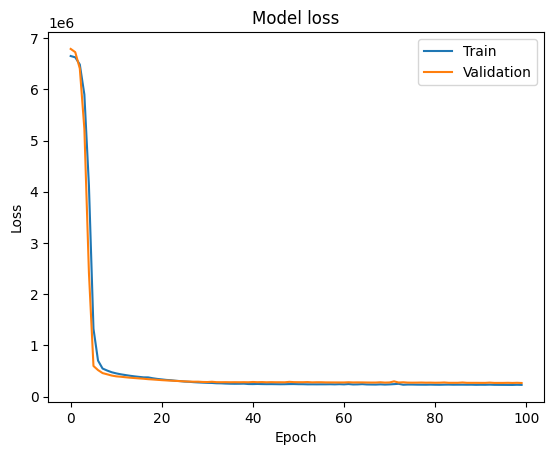

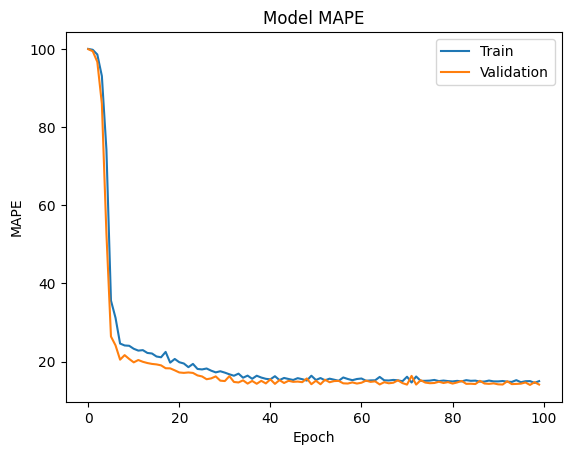

In [6]:
# Plot training & validation loss values
plt.plot(history.history['loss'])                        #Zeichnet den Trainings-MSE pro Epoche aus dem zuvor gespeicherten Trainingsverlauf
plt.plot(history.history['val_loss'])                    #Zeichnet den Validierungs-MSE zum Vergleich; diese Daten dienen nicht zur Gewichtsanpassung
plt.title('Model loss')                                  #Setzt den Titel des ersten Diagramms
plt.ylabel('Loss')                                       #Beschriftet die y-Achse: hier mittlerer quadratischer Fehler in CHF²
plt.xlabel('Epoch')                                      #Beschriftet die x-Achse mit den Trainingsepochen
plt.legend(['Train', 'Validation'], loc='upper right')   #Ordnet die Kurven Training und Validierung zu; zeigt die Legende oben rechts
plt.show()                                               #Zeigt das Loss-Diagramm an; kleinere Werte sind besser

# Plot training & validation MAPE values
plt.plot(history.history['mape'])                        #Zeichnet die mittlere absolute prozentuale Abweichung auf den Trainingsdaten
plt.plot(history.history['val_mape'])                    #Zeichnet dieselbe Kennzahl auf den Validierungsdaten zum Vergleich
plt.title('Model MAPE')                                  #Setzt den Titel des zweiten Diagramms
plt.ylabel('MAPE')                                       #Beschriftet die y-Achse: prozentualer Fehler, beispielsweise 15 für 15 %
plt.xlabel('Epoch')                                      #Beschriftet die x-Achse mit den Trainingsepochen
plt.legend(['Train', 'Validation'], loc='upper right')   #Kennzeichnet auch hier die beiden Kurven durch eine Legende
plt.show()                                               #Zeigt das MAPE-Diagramm an; kleinere Werte sind besser

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [7]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-26 07:27:11
Python Version: 3.11.17
-----------------------------------
